# Joint Model Notebook — SEG + TRA Cell Segmentation

This notebook **combines Model 1 (SEG / silver-truth)** and **Model 2 (TRA / gold-truth)** into a single, unified pipeline.

### What changes between the two tasks
| Aspect | Model 1 (SEG) | Model 2 (TRA) |
|--------|--------------|--------------|
| Ground-truth masks | Silver-truth `ST/SEG` | Gold-truth `GT/TRA` |
| Frames annotated | SEG-annotated frames only | Every tracked frame |
| Mask tuple index | index 1 | index 2 |
| Checkpoint suffix | `_seg` | `_tra` |

Everything else (architecture, hyperparameters, loss, split) is identical and runs **once** for both tasks.

### Workflow overview
1. Setup & install  
2. Download dataset & build pairs (SEG *and* TRA)  
3. Train/val/test split  
4. Visualise raw data  
5. Define shared helpers  
6. Load MedSAM  
7. Train ResNet-18 box predictor (SEG & TRA)  
8. Visualise box predictions  
9. Baseline evaluation (pretrained MedSAM)  
10. Fine-tune MedSAM — 4 experiments (Exp A/B × SEG/TRA)  
11. Final evaluation & comparison  
12. Qualitative visualisation

## Cell 1 — Install libraries & check device

In [ ]:
## ── Cell 1 : Install & imports ──────────────────────────────────────────
!pip -q install git+https://github.com/facebookresearch/segment-anything.git
!pip -q install monai tifffile imagecodecs gdown
!pip -q install -U scikit-image

import torch
print('Torch:', torch.__version__, '| CUDA:', torch.cuda.is_available())
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

import os, glob, cv2, numpy as np, tifffile as tiff
import matplotlib.pyplot as plt, matplotlib.patches as patches
import pandas as pd
from tqdm.auto import tqdm
import torchvision
from torchvision import transforms as T
from torch.utils.data import Dataset, DataLoader
from monai.losses import DiceLoss
from segment_anything.utils.transforms import ResizeLongestSide

print('numpy', np.__version__)

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 32.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.9/28.9 MB 67.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 93.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.5.1 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 113.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cucim-cu12 26.2.0 requires scikit-image<0.26.0,>=0.19.0, but you have scikit-image 0.26.0 which is incompatible.
Torch: 2.11.0+cu128 | CUDA: True
numpy 2.0.2


## Cell 2 — Download dataset & build pairs

We build **two** pair lists from the same DIC-C2DH-HeLa download:
- `pairs_seg` — iterates SEG silver-truth masks (Model 1)
- `pairs_tra` — iterates TRA gold-truth masks (Model 2)

In [ ]:
## ── Cell 2 : Download & build pairs ─────────────────────────────────────
!wget -q http://data.celltrackingchallenge.net/training-datasets/DIC-C2DH-HeLa.zip
!unzip -q -o DIC-C2DH-HeLa.zip -d data
ROOT = 'data/DIC-C2DH-HeLa'


# ── Model 1 pairs: anchor on ST/SEG silver-truth masks ───────────────────
def build_pairs_seg(root):
    """Each tuple: (img_path, seg_path, tra_path_or_None)"""
    pairs = []
    for seq in ['01', '02']:
        seg_dir = os.path.join(root, f'{seq}_ST', 'SEG')
        for seg_path in sorted(glob.glob(os.path.join(seg_dir, 'man_seg*.tif'))):
            t = ''.join(filter(str.isdigit, os.path.basename(seg_path)))[-3:]
            img_path = os.path.join(root, seq, f't{t}.tif')
            tra_path = os.path.join(root, f'{seq}_GT', 'TRA', f'man_track{t}.tif')
            if os.path.exists(img_path):
                pairs.append((
                    img_path,
                    seg_path,
                    tra_path if os.path.exists(tra_path) else None
                ))
    return pairs


# ── Model 2 pairs: anchor on GT/TRA gold-truth masks ─────────────────────
def build_pairs_tra(root):
    """Each tuple: (img_path, seg_path_or_None, tra_path)"""
    pairs = []
    for seq in ['01', '02']:
        tra_dir = os.path.join(root, f'{seq}_GT', 'TRA')
        for tra_path in sorted(glob.glob(os.path.join(tra_dir, 'man_track*.tif'))):
            t = ''.join(filter(str.isdigit, os.path.basename(tra_path)))[-3:]
            img_path = os.path.join(root, seq, f't{t}.tif')
            seg_dir  = os.path.join(root, f'{seq}_ST', 'SEG')
            seg_path = os.path.join(seg_dir, f'man_seg{t}.tif')
            if os.path.exists(img_path):
                pairs.append((
                    img_path,
                    seg_path if os.path.exists(seg_path) else None,
                    tra_path
                ))
    return pairs


pairs_seg = build_pairs_seg(ROOT)
pairs_tra = build_pairs_tra(ROOT)

print(f'SEG pairs : {len(pairs_seg)}')
print(f'TRA pairs : {len(pairs_tra)}  (more frames — every tracked frame is included)')

SEG pairs : 168
TRA pairs : 168  (more frames — every tracked frame is included)


## Cell 3 — Train / Val / Test split (60 / 20 / 20)

In [ ]:
## ── Cell 3 : Split ───────────────────────────────────────────────────────
def split_pairs(pairs, seed=42):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(pairs))
    n   = len(pairs)
    train = [pairs[i] for i in idx[:int(.6*n)]]
    val   = [pairs[i] for i in idx[int(.6*n):int(.8*n)]]
    test  = [pairs[i] for i in idx[int(.8*n):]]
    return train, val, test

train_seg, val_seg, test_seg = split_pairs(pairs_seg)
train_tra, val_tra, test_tra = split_pairs(pairs_tra)

print(f'SEG  → train={len(train_seg)}  val={len(val_seg)}  test={len(test_seg)}')
print(f'TRA  → train={len(train_tra)}  val={len(val_tra)}  test={len(test_tra)}')

SEG  → train=100  val=34  test=34
TRA  → train=100  val=34  test=34


## Cell 4 — Visualise raw data (SEG vs TRA mask)

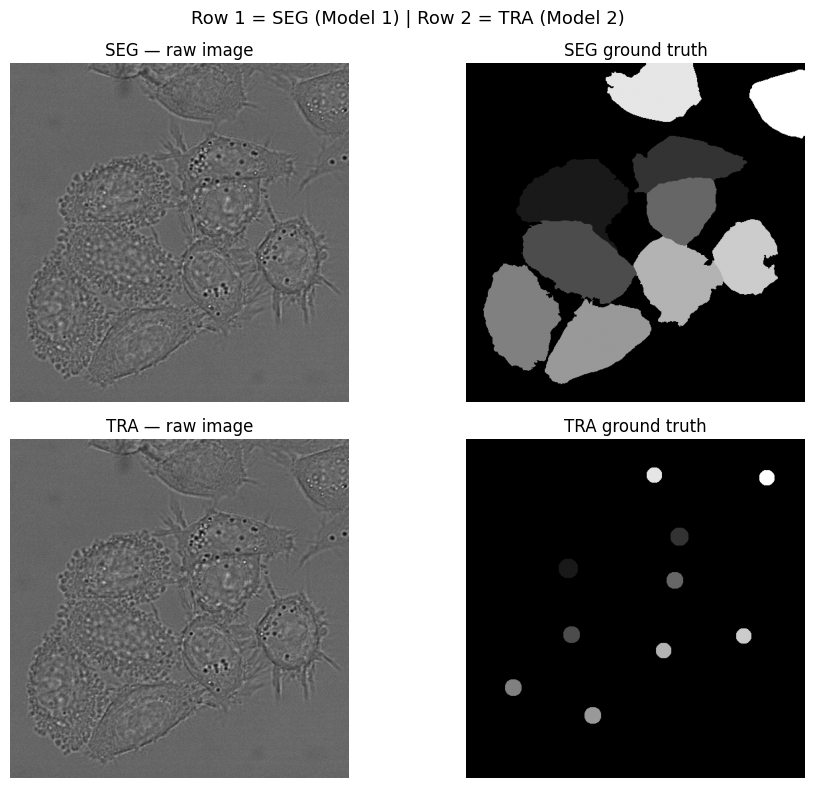

In [ ]:
## ── Cell 4 : Visualise ───────────────────────────────────────────────────
def instance_to_grayscale(mask):
    """Each instance gets a unique grayscale shade for display."""
    mask = mask.astype(np.int32)
    ids  = np.unique(mask); ids = ids[ids != 0]
    out  = np.zeros_like(mask, dtype=np.float32)
    for i, uid in enumerate(ids):
        out[mask == uid] = (i + 1) / len(ids)
    return out

# Show one SEG sample and one TRA sample side by side
img_s  = tiff.imread(pairs_seg[0][0])
seg_m  = tiff.imread(pairs_seg[0][1])

img_t  = tiff.imread(pairs_tra[0][0])
tra_m  = tiff.imread(pairs_tra[0][2])

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes[0,0].imshow(img_s,                     cmap='gray'); axes[0,0].set_title('SEG — raw image');  axes[0,0].axis('off')
axes[0,1].imshow(instance_to_grayscale(seg_m), cmap='gray', vmin=0, vmax=1); axes[0,1].set_title('SEG ground truth'); axes[0,1].axis('off')
axes[1,0].imshow(img_t,                     cmap='gray'); axes[1,0].set_title('TRA — raw image');  axes[1,0].axis('off')
axes[1,1].imshow(instance_to_grayscale(tra_m), cmap='gray', vmin=0, vmax=1); axes[1,1].set_title('TRA ground truth'); axes[1,1].axis('off')
plt.suptitle('Row 1 = SEG (Model 1) | Row 2 = TRA (Model 2)', fontsize=13)
plt.tight_layout(); plt.show()

## Cell 5 — Shared helper functions

In [ ]:
## ── Cell 5 : Shared helpers ──────────────────────────────────────────────
transform = ResizeLongestSide(1024)

def preprocess_image(img2d):
    """Grayscale → normalised RGB float32 in [0, 255]."""
    rgb = np.repeat(img2d[..., None].astype(np.float32), 3, axis=-1)
    return (rgb - rgb.min()) / (np.ptp(rgb) + 1e-8) * 255.0

def bbox_from_mask(bm):
    """Tight bounding box [x1, y1, x2, y2] around all non-zero pixels."""
    ys, xs = np.where(bm > 0)
    if len(xs) == 0:
        return None
    return [int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())]

def get_instance_boxes(mask):
    """One bounding box per instance ID."""
    ids = np.unique(mask); ids = ids[ids != 0]
    boxes = []
    for obj_id in ids:
        ys, xs = np.where(mask == obj_id)
        if len(xs) == 0: continue
        boxes.append((obj_id, np.array([xs.min(), ys.min(), xs.max(), ys.max()])))
    return boxes

def metrics(pred, gt):
    """Returns (Dice, IoU, Precision, Recall)."""
    pred, gt = pred.astype(bool), gt.astype(bool)
    inter = (pred & gt).sum()
    union = (pred | gt).sum()
    dice  = 2 * inter / (pred.sum() + gt.sum() + 1e-8)
    iou   = inter / (union + 1e-8)
    prec  = inter / (pred.sum() + 1e-8)
    rec   = inter / (gt.sum()   + 1e-8)
    return dice, iou, prec, rec

def box_iou(b1, b2):
    x1, y1 = max(b1[0], b2[0]), max(b1[1], b2[1])
    x2, y2 = min(b1[2], b2[2]), min(b1[3], b2[3])
    inter  = max(0, x2-x1) * max(0, y2-y1)
    a1 = (b1[2]-b1[0]) * (b1[3]-b1[1])
    a2 = (b2[2]-b2[0]) * (b2[3]-b2[1])
    return inter / (a1 + a2 - inter + 1e-8)

print('Shared helpers defined.')

Shared helpers defined.


## Cell 6 — Load MedSAM (pretrained)

In [ ]:
## ── Cell 6 : Load MedSAM ─────────────────────────────────────────────────
!wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth -O sam_vit_b.pth

# Try Google Drive first, fall back to Hugging Face mirror if it's rate-limited/blocked
!gdown -q 1UAmWL88roYR7wKlnApw5Bcuzf2iQgk6_ -O medsam_vit_b.pth || echo 'gdown failed, trying HF mirror...'

if not os.path.exists('medsam_vit_b.pth') or os.path.getsize('medsam_vit_b.pth') < 3e8:
    print('Falling back to Hugging Face mirror...')
    !wget -q https://huggingface.co/SansuiHan/medical_models/resolve/main/medsam_vit_b.pth -O medsam_vit_b.pth

if not os.path.exists('medsam_vit_b.pth') or os.path.getsize('medsam_vit_b.pth') < 3e8:
    raise RuntimeError('MedSAM checkpoint missing or corrupt.')

from segment_anything import sam_model_registry

def load_medsam(ckpt='medsam_vit_b.pth'):
    model = sam_model_registry['vit_b'](checkpoint=None)
    model.load_state_dict(torch.load(ckpt, map_location='cpu'), strict=False)
    return model.to(DEVICE)

medsam = load_medsam()
medsam.eval()
print('MedSAM loaded:', round(os.path.getsize('medsam_vit_b.pth') / 1e6, 1), 'MB')


@torch.no_grad()
def medsam_predict(model, img2d, box):
    """Single box → binary mask."""
    H, W = img2d.shape
    img_uint8  = preprocess_image(img2d).astype(np.uint8)
    in_img     = transform.apply_image(img_uint8)
    in_t       = torch.as_tensor(in_img).permute(2, 0, 1)[None].float().to(DEVICE)
    in_t       = model.preprocess(in_t)
    emb        = model.image_encoder(in_t)

    box_arr = np.array(box, dtype=np.float32)
    box_t   = torch.as_tensor(
        transform.apply_boxes(box_arr[None], (H, W)),
        dtype=torch.float, device=DEVICE)

    sparse_emb, dense_emb = model.prompt_encoder(points=None, boxes=box_t, masks=None)
    low_res, _            = model.mask_decoder(
        image_embeddings=emb,
        image_pe=model.prompt_encoder.get_dense_pe(),
        sparse_prompt_embeddings=sparse_emb,
        dense_prompt_embeddings=dense_emb,
        multimask_output=False)
    masks    = model.postprocess_masks(low_res, (1024, 1024), (H, W))
    pred     = torch.sigmoid(masks)[0, 0].cpu().numpy()
    return (pred > 0.5).astype(np.uint8)


@torch.no_grad()
def medsam_predict_multi(model, img2d, boxes):
    """Multiple boxes → merged binary mask (OR)."""
    H, W  = img2d.shape
    final = np.zeros((H, W), dtype=np.uint8)
    for box in boxes:
        final = np.maximum(final, medsam_predict(model, img2d, box))
    return final

Failed to retrieve file url:

	Too many users have viewed or downloaded this file recently. Please
	try accessing the file again later. If the file you are trying to
	access is particularly large or is shared with many people, it may
	take up to 24 hours to be able to view or download the file. If you
	still can't access a file after 24 hours, contact your domain
	administrator.

You may still be able to access the file from the browser:

	https://drive.google.com/uc?id=1UAmWL88roYR7wKlnApw5Bcuzf2iQgk6_

but Gdown can't. Please check connections and permissions.
gdown failed, trying HF mirror...
Falling back to Hugging Face mirror...
MedSAM loaded: 375.0 MB


## Cell 7 — Train ResNet-18 box predictor

Two ResNet-18 models are trained:
- `resnet_seg` — learns box positions from **SEG** masks (Model 1)
- `resnet_tra` — learns box positions from **TRA** masks (Model 2)

The pipeline for each: Otsu threshold → morphological cleanup → ResNet crop-refinement.

In [ ]:
## -- Cell 7 : Train Faster R-CNN Bounding Box Predictor (SEG & TRA) -- FIXED --
## Fix: replaced deprecated `pretrained=True` with `weights=...DEFAULT`,
## which is the current torchvision API. `pretrained=True` may raise a
## TypeError or be silently ignored depending on the installed torchvision
## version, so this makes the pretrained-weight loading explicit and safe.
##
## Update: train_faster_rcnn now saves a .pth checkpoint for each detector
## (best-loss checkpoint during training + a final save at the end), so both
## detector_seg and detector_tra are persisted to disk, not just kept in memory.

import random
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection import FasterRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

# 1. Define Faster R-CNN Model with ResNet-50-FPN Backbone
class CellDetectorFasterRCNN(torch.nn.Module):
    def __init__(self, num_classes=2): # Class 0 = Background, Class 1 = Cell
        super().__init__()
        self.model = fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT)
        in_features = self.model.roi_heads.box_predictor.cls_score.in_features
        self.model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

    def forward(self, images, targets=None):
        return self.model(images, targets)

# 2. Modern Full-Frame Bounding Box Dataset for Faster R-CNN
class FasterRCNNDataset(Dataset):
    def __init__(self, dataset_pairs, mask_index):
        """
        dataset_pairs: train_seg or train_tra list of path tuples
        mask_index: 1 for SEG (silver-truth), 2 for TRA (gold-truth)
        """
        self.pairs = [p for p in dataset_pairs if p[mask_index] is not None]
        self.mask_index = mask_index

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_path, mask_path = self.pairs[idx][0], self.pairs[idx][self.mask_index]

        # Load and normalize uncropped full frame image
        img = tiff.imread(img_path).astype(np.float32)
        img = (img - img.min()) / (np.ptp(img) + 1e-8)
        img_tensor = torch.tensor(img).unsqueeze(0).repeat(3, 1, 1) # Shape: [3, H, W]

        # Load instance mask containing multiple cells
        mask = tiff.imread(mask_path).astype(np.int32)
        obj_ids = np.unique(mask)
        obj_ids = obj_ids[obj_ids != 0] # Filter out the background

        boxes = []
        labels = []
        for oid in obj_ids:
            # Reusing the tight bbox helper from Cell 5
            b = bbox_from_mask((mask == oid).astype(np.uint8))
            if b is not None:
                x1, y1, x2, y2 = b
                if x2 > x1 and y2 > y1: # Verify box area validity
                    boxes.append([x1, y1, x2, y2])
                    labels.append(1) # Class 1 indicates 'cell'

        target = {}
        target["boxes"] = torch.as_tensor(boxes, dtype=torch.float32) if boxes else torch.zeros((0, 4), dtype=torch.float32)
        target["labels"] = torch.as_tensor(labels, dtype=torch.int64) if labels else torch.zeros((0,), dtype=torch.int64)

        return img_tensor, target

def collate_fn(batch):
    return tuple(zip(*batch))

# 3. Streamlined Training Loop using Architecture-Internal Losses
def train_faster_rcnn(train_pairs, mask_index, epochs=15, batch_size=4, lr=5e-4, tag='model', ckpt_name=None):
    """
    ckpt_name: if given, the model is checkpointed to this .pth path --
    the best (lowest avg_loss) epoch is saved as training progresses, and a
    final save is guaranteed at the end so a checkpoint always lands on disk.
    """
    dataset = FasterRCNNDataset(train_pairs, mask_index=mask_index)
    dl = DataLoader(dataset, batch_size=batch_size, shuffle=True, collate_fn=collate_fn)

    model = CellDetectorFasterRCNN(num_classes=2).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)

    best_loss = float('inf')
    for ep in range(epochs):
        model.train()
        total_loss = 0
        for images, targets in dl:
            images = [img.to(DEVICE) for img in images]
            targets = [{k: v.to(DEVICE) for k, v in t.items()} for t in targets]

            optimizer.zero_grad()
            loss_dict = model(images, targets)
            losses = sum(loss for loss in loss_dict.values()) # Auto-sums regression and classification losses

            losses.backward()
            optimizer.step()
            total_loss += losses.item()

        avg_loss = total_loss / len(dl)
        print(f'[{tag.upper()}] Epoch {ep+1}/{epochs}: avg_loss = {avg_loss:.4f}')

        if ckpt_name is not None and avg_loss < best_loss:
            best_loss = avg_loss
            torch.save(model.state_dict(), ckpt_name)
            print(f'  [OK][{tag.upper()}] new best checkpoint saved -> {ckpt_name} (avg_loss={avg_loss:.4f})')

    model.eval()

    if ckpt_name is not None:
        # Guarantee a checkpoint exists on disk even if avg_loss never beat best_loss
        # (e.g. epochs=1, or a run that plateaus immediately).
        if not os.path.exists(ckpt_name):
            torch.save(model.state_dict(), ckpt_name)
        print(f'[{tag.upper()}] Training complete. Checkpoint on disk: {ckpt_name} '
              f'({round(os.path.getsize(ckpt_name)/1e6, 1)} MB)')

    return model

# Train both detectors using the split segments
print("--- Training Faster R-CNN for SEG Task ---")
detector_seg = train_faster_rcnn(train_seg, mask_index=1, epochs=15, tag='seg',
                                  ckpt_name='fasterrcnn_seg.pth')

print("\n--- Training Faster R-CNN for TRA Task ---")
detector_tra = train_faster_rcnn(train_tra, mask_index=2, epochs=15, tag='tra',
                                  ckpt_name='fasterrcnn_tra.pth')

# Quick confirmation both checkpoints landed on disk
for f in ['fasterrcnn_seg.pth', 'fasterrcnn_tra.pth']:
    print(f, '->', 'FOUND OK' if os.path.exists(f) else 'MISSING')


## Cell 8 -- Visualise box predictions (SEG & TRA)

Shows a grid of test samples for **both** tasks: GT boxes (green, dashed) vs Faster R-CNN predicted boxes (red).

In [ ]:
## -- Cell 8 : Prediction Helpers & Visualisation ---------------------------
## Update: visualisation now covers BOTH tasks -- a grid of SEG box predictions
## AND a grid of TRA box predictions (previously only SEG was shown).

def predict_faster_rcnn_boxes(model, img2d, score_threshold=0.5):
    """Evaluates raw uncropped 2D frames and fetches precise bounding boxes."""
    model.eval()
    with torch.no_grad():
        img2d = img2d.astype(np.float32)  # FIX: force float32 to avoid DoubleTensor/FloatTensor mismatch
        img = (img2d - img2d.min()) / (np.ptp(img2d) + 1e-8)
        img_tensor = torch.tensor(img).float().unsqueeze(0).repeat(3, 1, 1).to(DEVICE)

        predictions = model([img_tensor])
        pred_boxes = predictions[0]['boxes'].cpu().numpy()
        pred_scores = predictions[0]['scores'].cpu().numpy()

        # Filter regions with high classification scores
        valid_idx = pred_scores >= score_threshold
        filtered_boxes = pred_boxes[valid_idx]

        return [box.astype(int).tolist() for box in filtered_boxes]

# n_boxes=None added so HeLaDataset's call (predict_fn(img, n_boxes=5)) doesn't crash
def predict_boxes_seg(img2d, n_boxes=None):
    return predict_faster_rcnn_boxes(detector_seg, img2d, score_threshold=0.5)

def predict_boxes_tra(img2d, n_boxes=None):
    return predict_faster_rcnn_boxes(detector_tra, img2d, score_threshold=0.5)


# -- Visualisation: GT boxes (green, dashed) vs Faster R-CNN predicted boxes (red) --
def visualize_box_predictions_grid(pairs, mask_index, predict_fn, task_label, n_samples=4, seed=0):
    """Row of n_samples test images: GT boxes (green dashed) vs model-predicted boxes (red)."""
    candidates = [p for p in pairs if p[mask_index] is not None]
    rng = np.random.default_rng(seed)
    n = min(n_samples, len(candidates))
    idxs = rng.choice(len(candidates), size=n, replace=False)

    fig, axes = plt.subplots(1, n, figsize=(5 * n, 5))
    if n == 1:
        axes = [axes]

    for col, i in enumerate(idxs):
        entry   = candidates[i]
        img_val = tiff.imread(entry[0]).astype(np.float32)
        gt_mask = tiff.imread(entry[mask_index]).astype(np.int32)

        predicted_boxes = predict_fn(img_val)
        gt_boxes        = [box.tolist() for _, box in get_instance_boxes(gt_mask)]

        ax = axes[col]
        ax.imshow(img_val, cmap='gray')

        for box in gt_boxes:
            x1, y1, x2, y2 = box
            rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                      linewidth=1.5, edgecolor='lime', linestyle='--', facecolor='none')
            ax.add_patch(rect)

        for box in predicted_boxes:
            x1, y1, x2, y2 = box
            rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                      linewidth=1.5, edgecolor='red', facecolor='none')
            ax.add_patch(rect)

        ax.set_title(f'{os.path.basename(entry[0])} ({len(predicted_boxes)} boxes)', fontsize=10)
        ax.axis('off')

    legend_handles = [
        patches.Patch(edgecolor='lime', facecolor='none', label='GT'),
        patches.Patch(edgecolor='red',  facecolor='none', label='Predicted'),
    ]
    fig.legend(handles=legend_handles, loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.05))
    fig.suptitle(f'{task_label} -- GT (green, dashed) vs Faster R-CNN predicted (red)', y=1.1, fontsize=13)
    plt.tight_layout()
    plt.show()


print('--- SEG box predictions ---')
visualize_box_predictions_grid(test_seg, mask_index=1, predict_fn=predict_boxes_seg,
                                task_label='SEG (Model 1)', n_samples=4)

print('--- TRA box predictions ---')
visualize_box_predictions_grid(test_tra, mask_index=2, predict_fn=predict_boxes_tra,
                                task_label='TRA (Model 2)', n_samples=4)


## Cell 9 — Inspect one test image per task

In [ ]:
## ── Cell 9 : Inspect test images ────────────────────────────────────────
def inspect_test_image(entry, mask_index, task_label):
    img_p  = entry[0]
    mask_p = entry[mask_index]
    gt     = tiff.imread(mask_p).astype(np.int32)
    H, W   = gt.shape
    ids    = np.unique(gt); ids = ids[ids != 0]
    print(f'\n[{task_label}]  image={os.path.basename(img_p)}  size=({W},{H})  objects={len(ids)}')
    for oid in ids:
        b = bbox_from_mask((gt == oid).astype(np.uint8))
        if b is None: continue
        x1,y1,x2,y2 = b
        print(f'  ID={oid}  box={b}  W={round((x2-x1)/W*100,1)}%  H={round((y2-y1)/H*100,1)}%')

inspect_test_image(test_seg[0], mask_index=1, task_label='SEG')
inspect_test_image(test_tra[0], mask_index=2, task_label='TRA')


[SEG]  image=t051.tif  size=(512,512)  objects=12
  ID=2  box=[56, 122, 161, 222]  W=20.5%  H=19.5%
  ID=4  box=[147, 142, 245, 241]  W=19.1%  H=19.3%
  ID=5  box=[38, 220, 152, 329]  W=22.3%  H=21.3%
  ID=9  box=[111, 228, 356, 403]  W=47.9%  H=34.2%
  ID=16  box=[288, 116, 450, 212]  W=31.6%  H=18.8%
  ID=17  box=[229, 122, 358, 281]  W=25.2%  H=31.1%
  ID=18  box=[336, 28, 511, 206]  W=34.2%  H=34.8%
  ID=22  box=[342, 225, 482, 421]  W=27.3%  H=38.3%
  ID=23  box=[193, 358, 395, 511]  W=39.5%  H=29.9%
  ID=26  box=[128, 406, 230, 511]  W=19.9%  H=20.5%
  ID=44  box=[41, 0, 154, 118]  W=22.1%  H=23.0%
  ID=45  box=[0, 7, 81, 142]  W=15.8%  H=26.4%

[TRA]  image=t051.tif  size=(512,512)  objects=13
  ID=2  box=[120, 161, 138, 179]  W=3.5%  H=3.5%
  ID=4  box=[193, 183, 211, 202]  W=3.5%  H=3.7%
  ID=5  box=[81, 244, 99, 262]  W=3.5%  H=3.5%
  ID=9  box=[224, 300, 242, 318]  W=3.5%  H=3.5%
  ID=16  box=[352, 163, 370, 181]  W=3.5%  H=3.5%
  ID=17  box=[290, 195, 308, 213]  W=3.5%  H=

## Cell 10 — Baseline evaluation (pretrained MedSAM, no fine-tuning)

In [ ]:
## ── Cell 10 : Baseline evaluation ───────────────────────────────────────
import inspect

def evaluate(model, dataset, predict_fn=None, mask_index=1, verbose=True):
    """
    predict_fn=None  → use perfect GT boxes (upper-bound baseline)
    predict_fn=fn    → use Faster R-CNN predicted boxes (realistic scenario)
    mask_index       → 1 for SEG, 2 for TRA
    """
    rows = []
    for entry in tqdm(dataset, desc='eval'):
        img_p  = entry[0]
        mask_p = entry[mask_index]
        if mask_p is None: continue

        img     = tiff.imread(img_p)
        gt_full = tiff.imread(mask_p).astype(np.int32)
        H, W    = gt_full.shape
        gt      = (gt_full > 0).astype(np.uint8)

        if predict_fn is not None:
            # Safely handle prediction parameters dynamically for Faster R-CNN
            sig = inspect.signature(predict_fn)
            if 'n_boxes' in sig.parameters:
                pred_boxes = predict_fn(img, n_boxes=5)
            else:
                pred_boxes = predict_fn(img)
        else:
            ids = np.unique(gt_full); ids = ids[ids != 0]
            pred_boxes = [b for b in
                          [bbox_from_mask((gt_full == oid).astype(np.uint8)) for oid in ids]
                          if b is not None]
        if not pred_boxes: continue

        final = np.zeros((H, W), dtype=np.uint8)
        for box in pred_boxes:
            pm = medsam_predict(model, img, box)
            if pm.shape != (H, W):
                pm = cv2.resize(pm, (W, H), interpolation=cv2.INTER_NEAREST)
            final = np.maximum(final, (pm > 0.5).astype(np.uint8))

        d, i, p, r = metrics(final, gt)
        rows.append({'image': os.path.basename(img_p),
                     'dice': round(d,3), 'iou': round(i,3),
                     'prec': round(p,3), 'rec': round(r,3)})

    res = pd.DataFrame(rows)
    if verbose and len(res):
        print(res.to_string(index=False))
        print(f'\nMean Dice: {res.dice.mean():.3f} ± {res.dice.std():.3f}'
              f' | Mean IoU: {res.iou.mean():.3f}')
    return (res.dice.mean(), res.iou.mean(),
            res.prec.mean(), res.rec.mean()) if len(res) else (0,0,0,0)


# ── SEG baseline ─────────────────────────────────────────────────────────
print('\n=== Pretrained MedSAM — SEG GT boxes (baseline) ===')
base_d_seg, base_i_seg, _, _ = evaluate(medsam, test_seg,
                                         predict_fn=None, mask_index=1)

# ── TRA baseline ─────────────────────────────────────────────────────────
print('\n=== Pretrained MedSAM — TRA GT boxes (baseline) ===')
base_d_tra, base_i_tra, _, _ = evaluate(medsam, test_tra,
                                         predict_fn=None, mask_index=2)


=== Pretrained MedSAM — SEG GT boxes (baseline) ===


eval:   0%|          | 0/34 [00:00<?, ?it/s]

   image  dice   iou  prec   rec
t051.tif 0.908 0.831 0.931 0.886
t023.tif 0.901 0.820 0.956 0.853
t058.tif 0.897 0.812 0.918 0.876
t015.tif 0.905 0.826 0.942 0.870
t060.tif 0.894 0.808 0.910 0.879
t025.tif 0.933 0.875 0.969 0.899
t053.tif 0.901 0.819 0.922 0.880
t031.tif 0.897 0.814 0.975 0.831
t016.tif 0.912 0.839 0.941 0.885
t044.tif 0.923 0.856 0.941 0.905
t072.tif 0.898 0.816 0.938 0.862
t034.tif 0.901 0.820 0.956 0.851
t030.tif 0.899 0.817 0.953 0.851
t058.tif 0.899 0.817 0.905 0.894
t035.tif 0.910 0.834 0.956 0.867
t077.tif 0.913 0.839 0.918 0.907
t049.tif 0.906 0.827 0.907 0.904
t006.tif 0.920 0.852 0.953 0.890
t018.tif 0.912 0.837 0.960 0.868
t055.tif 0.928 0.866 0.953 0.905
t071.tif 0.910 0.835 0.932 0.889
t041.tif 0.905 0.827 0.941 0.872
t026.tif 0.913 0.840 0.941 0.887
t022.tif 0.906 0.828 0.956 0.861
t019.tif 0.887 0.797 0.936 0.843
t064.tif 0.911 0.836 0.930 0.892
t047.tif 0.901 0.821 0.914 0.889
t029.tif 0.935 0.878 0.944 0.926
t056.tif 0.911 0.837 0.939 0.885
t014.tif 0

eval:   0%|          | 0/34 [00:00<?, ?it/s]

   image  dice   iou  prec   rec
t051.tif 0.593 0.421 0.942 0.433
t023.tif 0.526 0.357 0.985 0.359
t058.tif 0.530 0.360 0.952 0.367
t015.tif 0.571 0.400 0.968 0.405
t060.tif 0.596 0.425 0.970 0.430
t025.tif 0.449 0.289 0.937 0.295
t053.tif 0.616 0.445 0.938 0.458
t031.tif 0.532 0.363 0.958 0.369
t016.tif 0.449 0.290 0.937 0.296
t044.tif 0.557 0.386 0.985 0.388
t072.tif 0.637 0.468 0.925 0.486
t034.tif 0.487 0.322 0.951 0.327
t030.tif 0.556 0.385 0.963 0.391
t058.tif 0.545 0.375 0.976 0.379
t035.tif 0.582 0.410 0.962 0.417
t077.tif 0.541 0.371 0.945 0.379
t049.tif 0.524 0.355 0.977 0.358
t006.tif 0.422 0.267 0.958 0.270
t018.tif 0.551 0.380 0.933 0.391
t055.tif 0.623 0.453 0.916 0.472
t071.tif 0.532 0.363 0.949 0.370
t041.tif 0.608 0.437 0.978 0.442
t026.tif 0.462 0.300 0.869 0.315
t022.tif 0.477 0.313 0.991 0.314
t019.tif 0.551 0.380 0.974 0.384
t064.tif 0.566 0.395 0.964 0.401
t047.tif 0.550 0.380 0.975 0.383
t029.tif 0.506 0.339 0.894 0.353
t056.tif 0.601 0.430 0.972 0.435
t014.tif 0

## Cell 11 — Dataset class & fine-tune function

In [ ]:
## ── Cell 11 : Dataset & fine-tune ───────────────────────────────────────
def collate(batch): return batch[0]   # batch_size = 1

class HeLaDataset(Dataset):
    def __init__(self, pairs, predict_fn=None, mask_index=1):
        """
        predict_fn=None  → GT boxes  (Exp B)
        predict_fn=fn    → ResNet boxes (Exp A)
        mask_index       → 1 = SEG, 2 = TRA
        """
        self.pairs      = pairs
        self.predict_fn = predict_fn
        self.mask_index = mask_index

    def __len__(self): return len(self.pairs)

    def __getitem__(self, i):
        entry  = self.pairs[i]
        img_p  = entry[0]
        mask_p = entry[self.mask_index]

        img = tiff.imread(img_p)
        H, W = img.shape

        if mask_p is None:                              # fallback: black mask
            gt    = np.zeros((H, W), dtype=np.uint8)
            boxes = np.array([[0, 0, W-1, H-1]], dtype=np.float32)
        else:
            gt_full = tiff.imread(mask_p).astype(np.int32)
            gt      = (gt_full > 0).astype(np.uint8)
            if self.predict_fn is not None:
                boxes = self.predict_fn(img, n_boxes=5)
            else:
                ids   = np.unique(gt_full); ids = ids[ids != 0]
                boxes = [b for b in
                         [bbox_from_mask((gt_full==oid).astype(np.uint8)) for oid in ids]
                         if b is not None]
            if not boxes:
                boxes = [[0, 0, W-1, H-1]]

        rgb   = transform.apply_image(preprocess_image(img).astype(np.uint8))
        boxes = transform.apply_boxes(np.array(boxes, dtype=np.float32), (H, W))
        return (
            torch.as_tensor(rgb).permute(2, 0, 1).float(),
            torch.tensor(gt).unsqueeze(0).float(),
            torch.tensor(boxes).float(),
            (H, W)
        )


dice_loss = DiceLoss(sigmoid=True)
bce       = torch.nn.BCEWithLogitsLoss()
scaler    = torch.cuda.amp.GradScaler(enabled=(DEVICE == 'cuda'))


def forward_logits(model, img_t, boxes, hw):
    H, W   = hw
    img_t  = img_t.to(DEVICE)
    boxes  = boxes.to(DEVICE)
    in_t   = model.preprocess(img_t.unsqueeze(0))
    with torch.no_grad():
        emb = model.image_encoder(in_t)
    sparse_emb, dense_emb = model.prompt_encoder(points=None, boxes=boxes, masks=None)
    low_res, _ = model.mask_decoder(
        image_embeddings=emb,
        image_pe=model.prompt_encoder.get_dense_pe(),
        sparse_prompt_embeddings=sparse_emb,
        dense_prompt_embeddings=dense_emb,
        multimask_output=False)
    logits = model.postprocess_masks(low_res, (1024, 1024), (H, W))
    return logits.amax(dim=0, keepdim=True)


def fine_tune(model, train_dl, val_dl, epochs=20, lr=1e-4,
              ckpt_name='model.pth', tag='FT', mask_index=1):
    for p in model.image_encoder.parameters():  p.requires_grad = False
    for p in model.prompt_encoder.parameters(): p.requires_grad = False
    for p in model.mask_decoder.parameters():   p.requires_grad = True

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    best_dice = -1

    for ep in range(epochs):
        model.train(); total_loss = 0
        for img_t, gt, boxes, hw in tqdm(train_dl, desc=f'{tag} ep{ep}'):
            gt = gt.unsqueeze(0).to(DEVICE)
            optimizer.zero_grad()
            with torch.cuda.amp.autocast(enabled=(DEVICE == 'cuda')):
                logits = forward_logits(model, img_t, boxes, hw)
                loss   = dice_loss(logits, gt) + bce(logits, gt)
            scaler.scale(loss).backward()
            scaler.step(optimizer); scaler.update()
            total_loss += loss.item()
        scheduler.step()

        model.eval(); vd = vi = n = 0
        with torch.no_grad():
            for img_t, gt, boxes, hw in val_dl:
                logits = forward_logits(model, img_t, boxes, hw)
                pred   = (torch.sigmoid(logits)[0,0].cpu().numpy() > 0.5).astype(np.uint8)
                d, i, _, _ = metrics(pred, gt[0].numpy())
                vd += d; vi += i; n += 1
        vd /= n; vi /= n
        print(f'{tag} ep{ep}: loss={total_loss/len(train_dl):.4f} | val_dice={vd:.4f}')
        if vd > best_dice:
            best_dice = vd
            torch.save(model.state_dict(), ckpt_name)
            print('  ✅ saved best model')

print('Dataset class and fine_tune() ready.')

Dataset class and fine_tune() ready.


/tmp/ipykernel_1139/945023224.py:53: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler    = torch.cuda.amp.GradScaler(enabled=(DEVICE == 'cuda'))


## Cell 12 — Fine-tune MedSAM: 4 experiments

| Exp | Task | Box source | Checkpoint |
|-----|------|-----------|------------|
| A-SEG | SEG | ResNet predicted | `medsam_seg_predbox.pth` |
| B-SEG | SEG | GT (perfect) | `medsam_seg_gtbox.pth` |
| A-TRA | TRA | ResNet predicted | `medsam_tra_predbox.pth` |
| B-TRA | TRA | GT (perfect) | `medsam_tra_gtbox.pth` |

In [ ]:
## ── Cell 12 : Fine-tune — 2 experiments (Exp A & Exp B) ──────────────────

# =========================================================================
# ─── EXPERIMENT A : Train on Faster R-CNN / Test on Faster R-CNN ─────────
# =========================================================================

# ─── Exp A-SEG : Faster R-CNN boxes, trained on SEG ──────────────────────
print('\n====== Exp A-SEG : Faster R-CNN boxes, SEG masks ======')
medsam_expA_seg = load_medsam()
if DEVICE == 'cuda': torch.cuda.empty_cache()

dl_train_A_seg = DataLoader(HeLaDataset(train_seg, predict_fn=predict_boxes_seg, mask_index=1),
                            batch_size=1, shuffle=True,  collate_fn=collate, num_workers=0,
                            pin_memory=(DEVICE=='cuda'))
dl_val_A_seg   = DataLoader(HeLaDataset(val_seg,   predict_fn=predict_boxes_seg, mask_index=1),
                            batch_size=1, shuffle=False, collate_fn=collate, num_workers=0,
                            pin_memory=(DEVICE=='cuda'))
fine_tune(medsam_expA_seg, dl_train_A_seg, dl_val_A_seg, epochs=20, lr=1e-4,
          ckpt_name='medsam_seg_predbox.pth', tag='A-SEG')


# ─── Exp A-TRA : Faster R-CNN boxes, trained on TRA ──────────────────────
print('\n====== Exp A-TRA : Faster R-CNN boxes, TRA masks ======')
medsam_expA_tra = load_medsam()
if DEVICE == 'cuda': torch.cuda.empty_cache()

dl_train_A_tra = DataLoader(HeLaDataset(train_tra, predict_fn=predict_boxes_tra, mask_index=2),
                            batch_size=1, shuffle=True,  collate_fn=collate, num_workers=0,
                            pin_memory=(DEVICE=='cuda'))
dl_val_A_tra   = DataLoader(HeLaDataset(val_tra,   predict_fn=predict_boxes_tra, mask_index=2),
                            batch_size=1, shuffle=False, collate_fn=collate, num_workers=0,
                            pin_memory=(DEVICE=='cuda'))
fine_tune(medsam_expA_tra, dl_train_A_tra, dl_val_A_tra, epochs=20, lr=1e-4,
          ckpt_name='medsam_tra_predbox.pth', tag='A-TRA')


# =========================================================================
# ─── EXPERIMENT B : Train on GT/ST boxes / Test on Faster R-CNN ──────────
# =========================================================================

# ─── Exp B-SEG : GT boxes, trained on SEG ───────────────────────────────
print('\n====== Exp B-SEG : GT boxes, SEG masks ======')
medsam_expB_seg = load_medsam()
if DEVICE == 'cuda': torch.cuda.empty_cache()

dl_train_B_seg = DataLoader(HeLaDataset(train_seg, predict_fn=None, mask_index=1),
                            batch_size=1, shuffle=True,  collate_fn=collate, num_workers=0,
                            pin_memory=(DEVICE=='cuda'))
dl_val_B_seg   = DataLoader(HeLaDataset(val_seg,   predict_fn=None, mask_index=1),
                            batch_size=1, shuffle=False, collate_fn=collate, num_workers=0,
                            pin_memory=(DEVICE=='cuda'))
fine_tune(medsam_expB_seg, dl_train_B_seg, dl_val_B_seg, epochs=20, lr=1e-4,
          ckpt_name='medsam_seg_gtbox.pth', tag='B-SEG')


# ─── Exp B-TRA : GT boxes, trained on TRA ───────────────────────────────
print('\n====== Exp B-TRA : GT boxes, TRA masks ======')
medsam_expB_tra = load_medsam()
if DEVICE == 'cuda': torch.cuda.empty_cache()

dl_train_B_tra = DataLoader(HeLaDataset(train_tra, predict_fn=None, mask_index=2),
                            batch_size=1, shuffle=True,  collate_fn=collate, num_workers=0,
                            pin_memory=(DEVICE=='cuda'))
dl_val_B_tra   = DataLoader(HeLaDataset(val_tra,   predict_fn=None, mask_index=2),
                            batch_size=1, shuffle=False, collate_fn=collate, num_workers=0,
                            pin_memory=(DEVICE=='cuda'))
fine_tune(medsam_expB_tra, dl_train_B_tra, dl_val_B_tra, epochs=20, lr=1e-4,
          ckpt_name='medsam_tra_gtbox.pth', tag='B-TRA')

print('\nFine-tuning complete for both Experiment A (Pred Box) and Experiment B (GT Box) tasks.')


====== Exp A-SEG : Faster R-CNN boxes, SEG masks ======


A-SEG ep0:   0%|          | 0/100 [00:00<?, ?it/s]

/tmp/ipykernel_1139/945023224.py:91: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(DEVICE == 'cuda')):


A-SEG ep0: loss=0.2935 | val_dice=0.9239
  ✅ saved best model


A-SEG ep1:   0%|          | 0/100 [00:00<?, ?it/s]

A-SEG ep1: loss=0.2482 | val_dice=0.9303
  ✅ saved best model


... (152 outputs left out)

B-TRA ep18:   0%|          | 0/100 [00:00<?, ?it/s]

B-TRA ep18: loss=0.0144 | val_dice=0.9828
  ✅ saved best model


B-TRA ep19:   0%|          | 0/100 [00:00<?, ?it/s]

B-TRA ep19: loss=0.0143 | val_dice=0.9828

Fine-tuning complete for both Experiment A (Pred Box) and Experiment B (GT Box) tasks.


In [ ]:
import os
files = ['medsam_seg_predbox.pth', 'medsam_seg_gtbox.pth', 'medsam_tra_predbox.pth', 'medsam_tra_gtbox.pth']
for f in files:
    print(f, '→', 'FOUND ✅' if os.path.exists(f) else 'MISSING ❌')

medsam_seg_predbox.pth → FOUND ✅
medsam_seg_gtbox.pth → FOUND ✅
medsam_tra_predbox.pth → FOUND ✅
medsam_tra_gtbox.pth → FOUND ✅


## Cell 13 — Final evaluation & comparison table

In [ ]:
## ── Cell 13 : Load checkpoints & test Exp A and Exp B ──────

# ═══════════════════════════════════════════════════════════════
# Exp A : trained on GT boxes / tested with Faster R-CNN boxes
# ═══════════════════════════════════════════════════════════════
medsam_expB_seg = load_medsam()
medsam_expB_seg.load_state_dict(torch.load('medsam_seg_gtbox.pth', map_location=DEVICE))
medsam_expB_seg.to(DEVICE); medsam_expB_seg.eval()

medsam_expB_tra = load_medsam()
medsam_expB_tra.load_state_dict(torch.load('medsam_tra_gtbox.pth', map_location=DEVICE))
medsam_expB_tra.to(DEVICE); medsam_expB_tra.eval()

print('Evaluating — SEG task (train GT / test ResNet) ...')
bB_seg_d, bB_seg_i, _, _ = evaluate(medsam_expB_seg, test_seg, predict_fn=predict_boxes_seg, mask_index=1, verbose=False)

print('Evaluating — TRA task (train GT / test ResNet) ...')
bB_tra_d, bB_tra_i, _, _ = evaluate(medsam_expB_tra, test_tra, predict_fn=predict_boxes_tra, mask_index=2, verbose=False)


# ═══════════════════════════════════════════════════════════════
# Exp B : trained on Faster R-CNN boxes / tested with Faster R-CNN boxes
# ═══════════════════════════════════════════════════════════════
medsam_expA_seg = load_medsam()
medsam_expA_seg.load_state_dict(torch.load('medsam_seg_predbox.pth', map_location=DEVICE))
medsam_expA_seg.to(DEVICE); medsam_expA_seg.eval()

medsam_expA_tra = load_medsam()
medsam_expA_tra.load_state_dict(torch.load('medsam_tra_predbox.pth', map_location=DEVICE))
medsam_expA_tra.to(DEVICE); medsam_expA_tra.eval()

print('Evaluating — SEG task (train Faster R-CNN / test Faster R-CNN) ...')
aB_seg_d, aB_seg_i, _, _ = evaluate(medsam_expA_seg, test_seg, predict_fn=predict_boxes_seg, mask_index=1, verbose=False)

print('Evaluating — TRA task (train Faster R-CNN / test Faster R-CNN) ...')
aB_tra_d, aB_tra_i, _, _ = evaluate(medsam_expA_tra, test_tra, predict_fn=predict_boxes_tra, mask_index=2, verbose=False)


# ═══════════════════════════════════════════════════════════════
# Combined summary table
# ═══════════════════════════════════════════════════════════════
cmp_all = pd.DataFrame({
    'Task':  ['SEG', 'TRA', 'SEG', 'TRA'],
    'Model': ['Exp A (train GT / test Faster R-CNN)',
              'Exp A (train GT / test Faster R-CNN)',
              'Exp B (train Faster R-CNN / test Faster R-CNN)',
              'Exp B (train Faster R-CNN / test Faster R-CNN)'],
    'Dice':  [round(bB_seg_d,3), round(bB_tra_d,3), round(aB_seg_d,3), round(aB_tra_d,3)],
    'IoU':   [round(bB_seg_i,3), round(bB_tra_i,3), round(aB_seg_i,3), round(aB_tra_i,3)],
})

print('\n=== Exp A vs Exp B Comparison (both tested on Faster R-CNN boxes) ===')
print(cmp_all.to_string(index=False))

Evaluating — SEG task (train GT / test ResNet) ...


eval:   0%|          | 0/34 [00:00<?, ?it/s]

Evaluating — TRA task (train GT / test ResNet) ...


eval:   0%|          | 0/34 [00:00<?, ?it/s]


=== Train-GT / Test-ResNet Comparison ===
Task                                     Model  Dice   IoU
 SEG Fine-tuned Exp B (train GT / test ResNet) 0.930 0.870
 TRA Fine-tuned Exp B (train GT / test ResNet) 0.445 0.294


## Cell 14 — Qualitative visualisation

--- SEG : before vs after fine-tuning (Exp B) ---


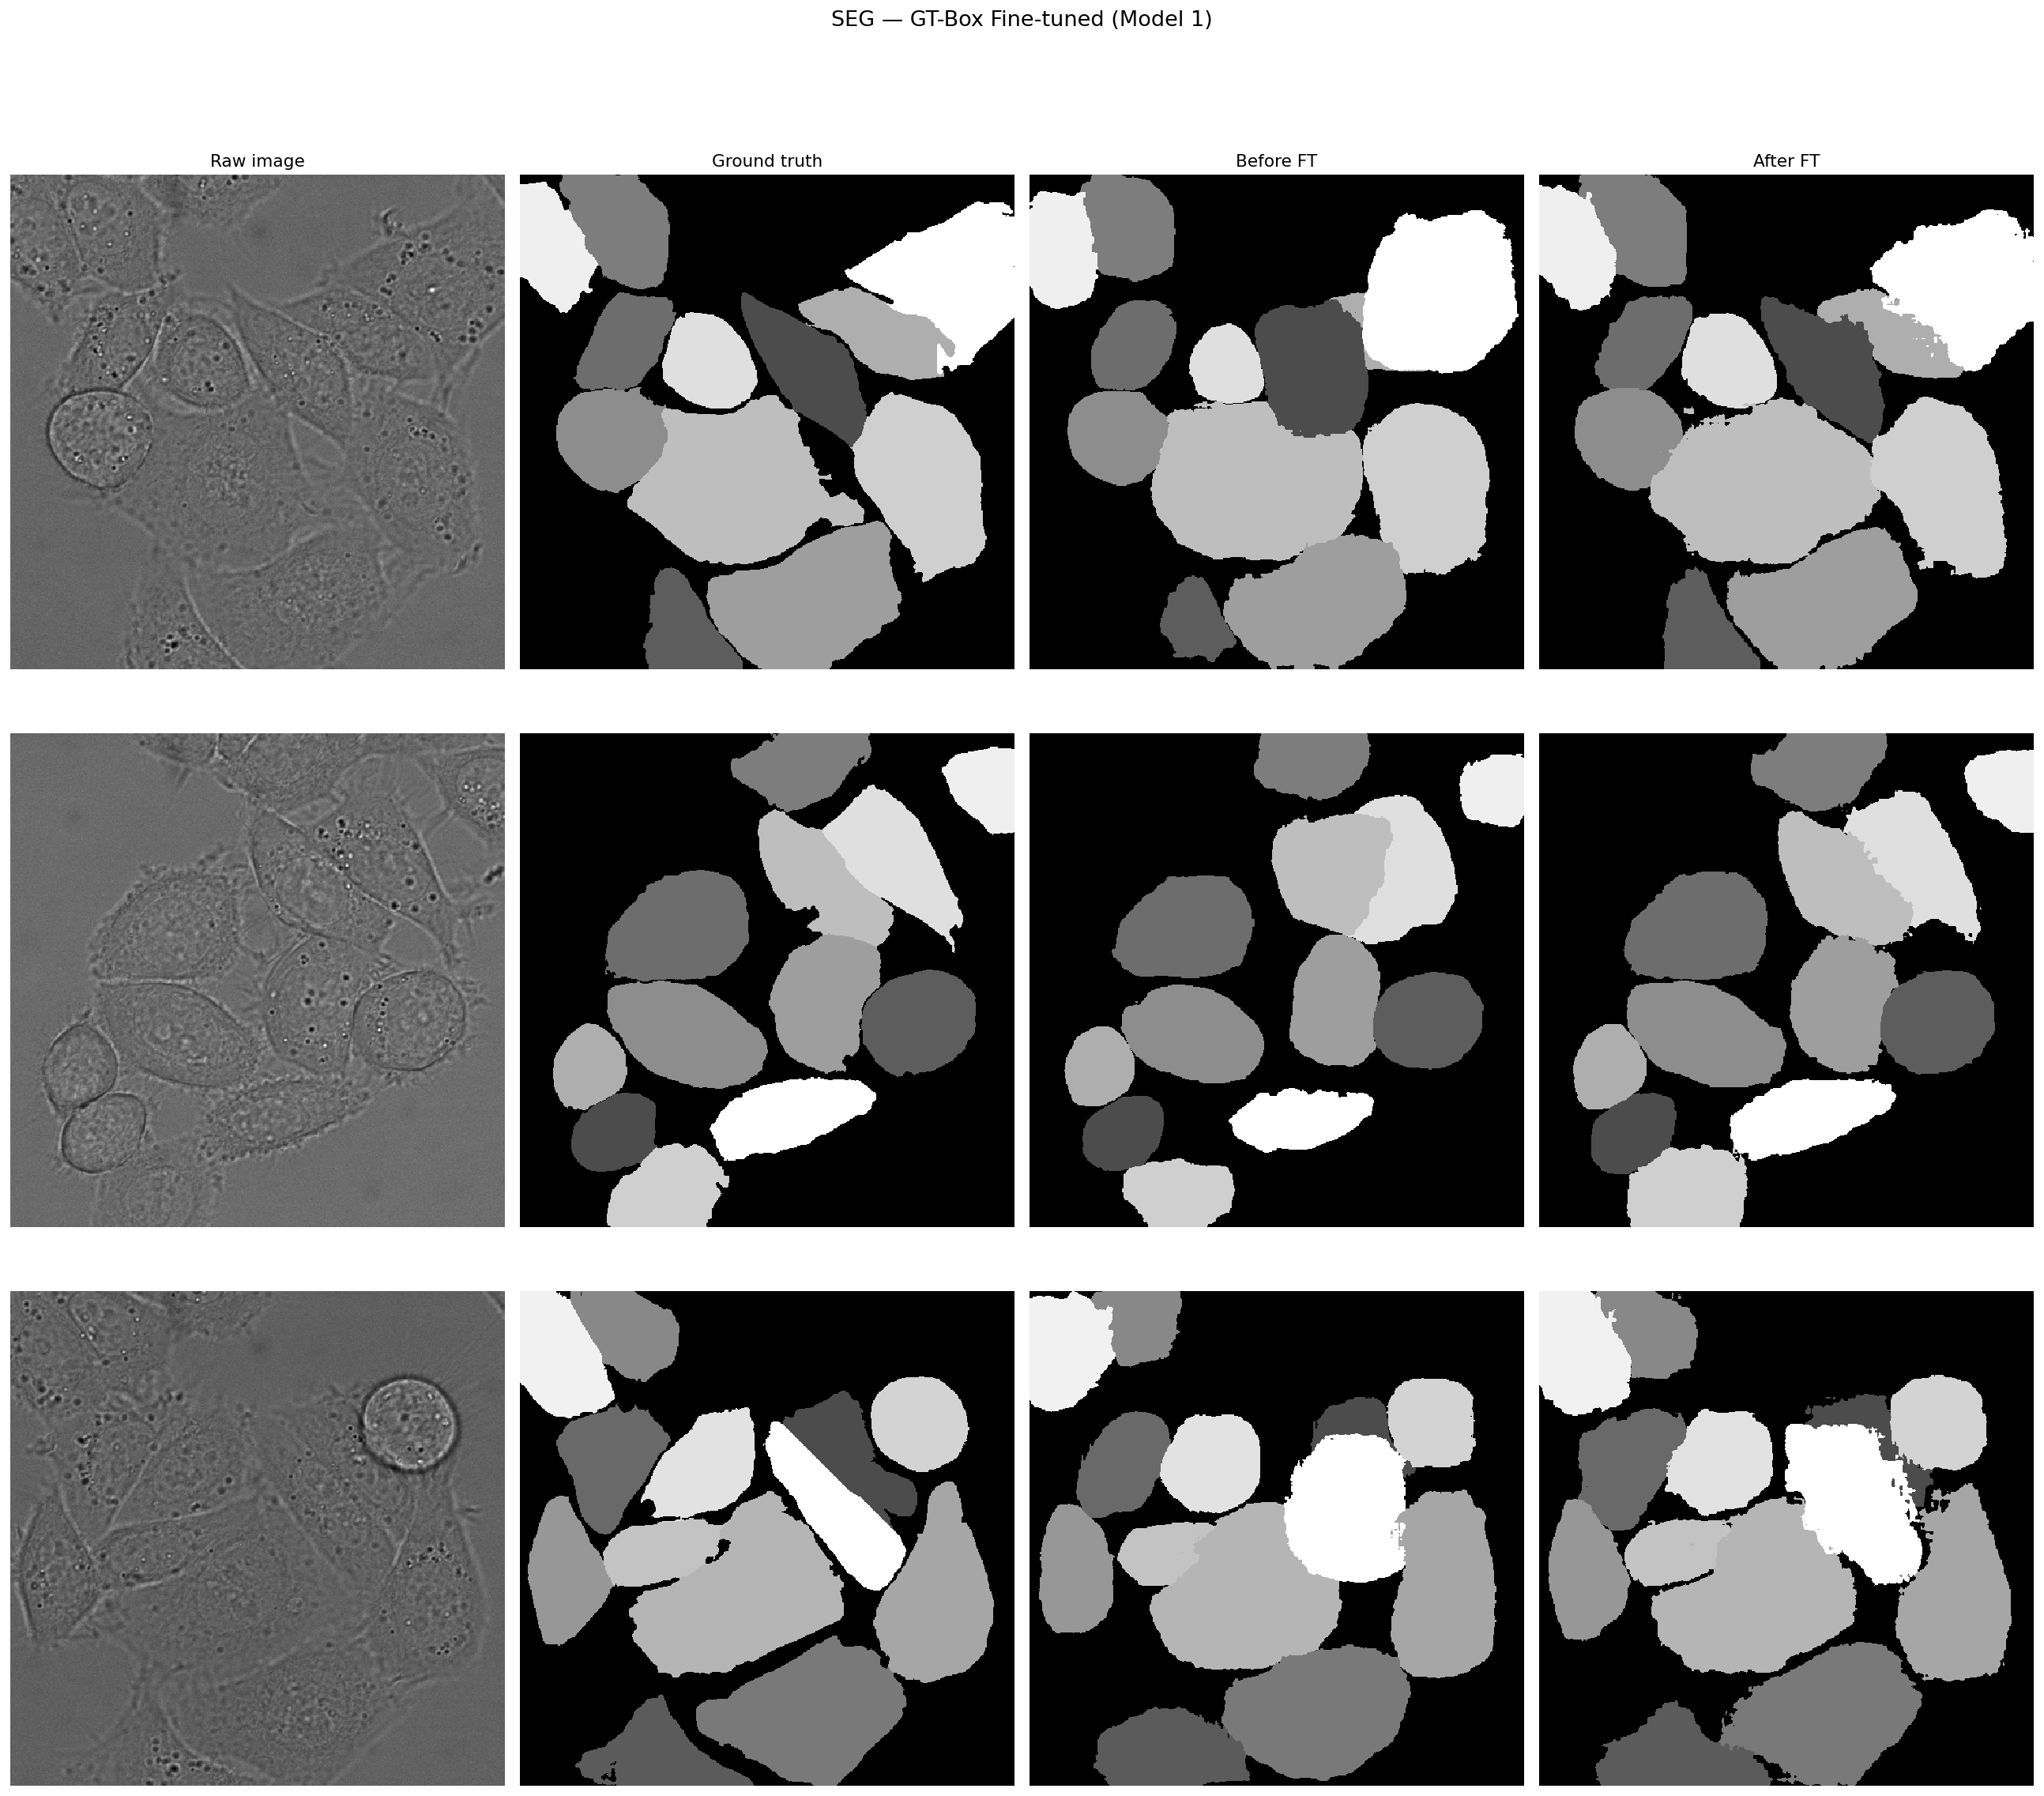

--- TRA : before vs after fine-tuning (Exp B) ---


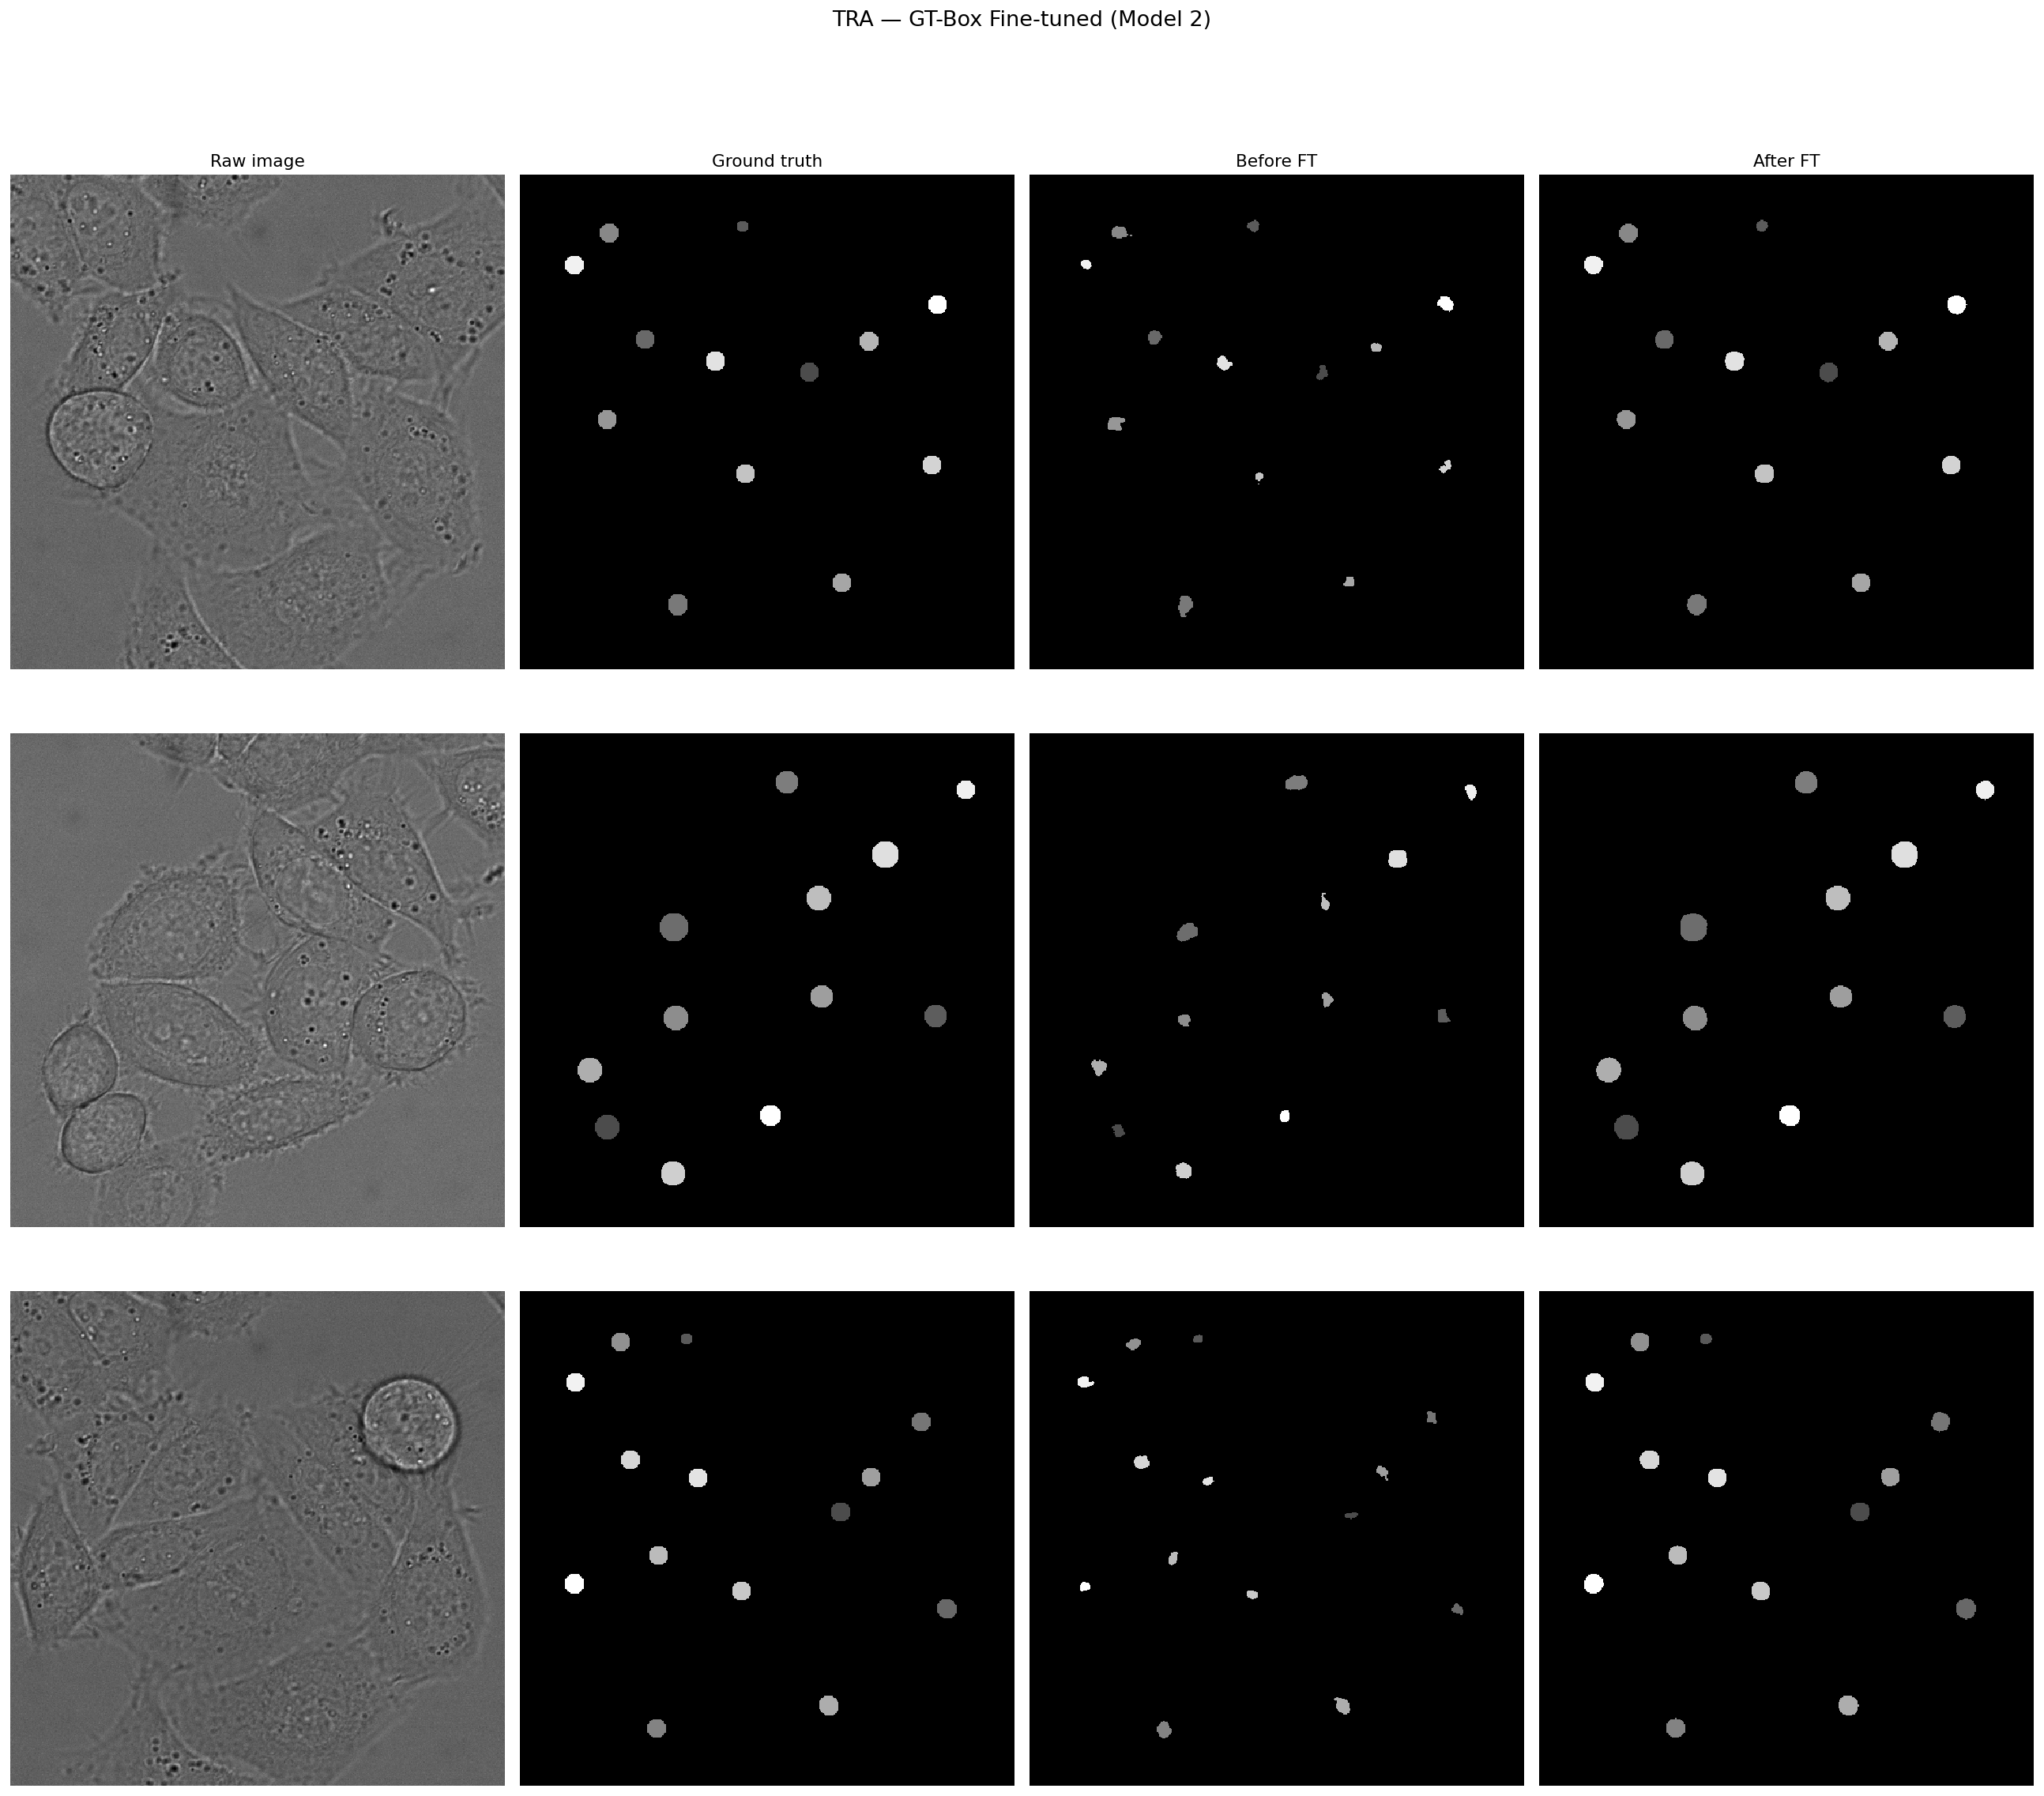

In [ ]:
## ── Cell 14 : Qualitative visualisation ─────────────────────────────────

def instance_to_sharp_grayscale(inst_map):
    inst_map = inst_map.astype(np.int32)
    ids      = np.unique(inst_map); ids = ids[ids != 0]
    out      = np.zeros(inst_map.shape, dtype=float)
    if len(ids) == 0: return out
    levels   = np.linspace(1.0, 0.3, len(ids))
    np.random.default_rng(0).shuffle(levels)
    for uid, g in zip(ids, levels):
        out[inst_map == uid] = g
    return out


def boxes_to_instance_grayscale(model, img2d, boxes):
    """Run MedSAM per box and assign each a unique shade — avoids cell merging in display."""
    H, W     = img2d.shape
    inst_map = np.zeros((H, W), dtype=np.int32)
    for nxt, box in enumerate(boxes, 1):
        m = medsam_predict(model, img2d, box) > 0
        inst_map[m] = nxt
    return instance_to_sharp_grayscale(inst_map)


def show_final(samples, model_before, model_after, mask_index, title):
    cols = ['Raw image', 'Ground truth', 'Before FT', 'After FT']
    fig, ax = plt.subplots(len(samples), 4,
                           figsize=(20, 6*len(samples)), dpi=130)
    if len(samples) == 1: ax = [ax]

    for r, entry in enumerate(samples):
        img_p  = entry[0]
        mask_p = entry[mask_index]
        img    = tiff.imread(img_p)
        gt_inst = tiff.imread(mask_p).astype(np.int32)
        gt_disp = instance_to_sharp_grayscale(gt_inst)

        ids   = np.unique(gt_inst); ids = ids[ids != 0]
        boxes = [b for b in [bbox_from_mask((gt_inst==oid).astype(np.uint8)) for oid in ids] if b]
        if not boxes:
            H, W = img.shape; boxes = [[0, 0, W-1, H-1]]

        pre_disp  = boxes_to_instance_grayscale(model_before, img, boxes)
        post_disp = boxes_to_instance_grayscale(model_after,  img, boxes)

        for c, (im, cmap_kw) in enumerate(
            [(img,      {'cmap':'gray'}),
             (gt_disp,  {'cmap':'gray','vmin':0,'vmax':1}),
             (pre_disp, {'cmap':'gray','vmin':0,'vmax':1}),
             (post_disp,{'cmap':'gray','vmin':0,'vmax':1})]):
            a = ax[r][c]
            a.imshow(im, interpolation='none', **cmap_kw)
            a.axis('off')
            if r == 0: a.set_title(cols[c], fontsize=12)

    plt.suptitle(title, fontsize=15, y=1.0)
    plt.subplots_adjust(wspace=0.02, hspace=0.05)
    plt.tight_layout(rect=[0,0,1,0.97]); plt.show()


# ── SEG : pretrained vs Exp B (GT boxes, best scenario) ──────────────────
print('--- SEG : before vs after fine-tuning (Exp B) ---')
show_final(test_seg[:3], medsam, medsam_expB_seg, mask_index=1,
           title='SEG — GT-Box Fine-tuned (Model 1)')

# ── TRA : pretrained vs Exp B (GT boxes, best scenario) ──────────────────
print('--- TRA : before vs after fine-tuning (Exp B) ---')
show_final(test_tra[:3], medsam, medsam_expB_tra, mask_index=2,
           title='TRA — GT-Box Fine-tuned (Model 2)')

In [ ]:
## ── New Cell : Exp A (instructed) — train on GT boxes, test on ResNet boxes ──

# Reuse the already-trained GT-box checkpoints (no retraining needed)
medsam_expB_seg = load_medsam()
medsam_expB_seg.load_state_dict(torch.load('medsam_seg_gtbox.pth', map_location=DEVICE))
medsam_expB_seg.to(DEVICE); medsam_expB_seg.eval()

medsam_expB_tra = load_medsam()
medsam_expB_tra.load_state_dict(torch.load('medsam_tra_gtbox.pth', map_location=DEVICE))
medsam_expB_tra.to(DEVICE); medsam_expB_tra.eval()

# Evaluate the GT-trained model, but feed it ResNet-predicted boxes at test time
print('Evaluating — SEG (trained on GT, tested on ResNet boxes) ...')
mismatch_seg_d, mismatch_seg_i, _, _ = evaluate(
    medsam_expB_seg, test_seg, predict_fn=predict_boxes_seg, mask_index=1, verbose=False
)

print('Evaluating — TRA (trained on GT, tested on ResNet boxes) ...')
mismatch_tra_d, mismatch_tra_i, _, _ = evaluate(
    medsam_expB_tra, test_tra, predict_fn=predict_boxes_tra, mask_index=2, verbose=False
)

print(f'\nSEG — trained GT / tested ResNet:  Dice={mismatch_seg_d:.3f}  IoU={mismatch_seg_i:.3f}')
print(f'TRA — trained GT / tested ResNet:  Dice={mismatch_tra_d:.3f}  IoU={mismatch_tra_i:.3f}')

Evaluating — SEG (trained on GT, tested on ResNet boxes) ...


eval:   0%|          | 0/34 [00:00<?, ?it/s]

Evaluating — TRA (trained on GT, tested on ResNet boxes) ...


eval:   0%|          | 0/34 [00:00<?, ?it/s]


SEG — trained GT / tested ResNet:  Dice=0.930  IoU=0.870
TRA — trained GT / tested ResNet:  Dice=0.445  IoU=0.294


In [ ]:
## ── Cell 13 : Load checkpoints & test Exp A and Exp B ──────
# ═══════════════════════════════════════════════════════════════
# Exp B : trained on Faster R-CNN boxes / tested with Faster R-CNN boxes
# ═══════════════════════════════════════════════════════════════
medsam_expA_seg = load_medsam()
medsam_expA_seg.load_state_dict(torch.load('medsam_seg_predbox.pth', map_location=DEVICE))
medsam_expA_seg.to(DEVICE); medsam_expA_seg.eval()

medsam_expA_tra = load_medsam()
medsam_expA_tra.load_state_dict(torch.load('medsam_tra_predbox.pth', map_location=DEVICE))
medsam_expA_tra.to(DEVICE); medsam_expA_tra.eval()

print('Evaluating — SEG task (train Faster R-CNN / test Faster R-CNN) ...')
aB_seg_d, aB_seg_i, _, _ = evaluate(medsam_expA_seg, test_seg, predict_fn=predict_boxes_seg, mask_index=1, verbose=False)

print('Evaluating — TRA task (train Faster R-CNN / test Faster R-CNN) ...')
aB_tra_d, aB_tra_i, _, _ = evaluate(medsam_expA_tra, test_tra, predict_fn=predict_boxes_tra, mask_index=2, verbose=False)


# ═══════════════════════════════════════════════════════════════
# Combined summary table
# ═══════════════════════════════════════════════════════════════
cmp_all = pd.DataFrame({
    'Task':  ['SEG', 'TRA', 'SEG', 'TRA'],
    'Model': ['Exp A (train GT / test Faster R-CNN)',
              'Exp A (train GT / test Faster R-CNN)',
              'Exp B (train Faster R-CNN / test Faster R-CNN)',
              'Exp B (train Faster R-CNN / test Faster R-CNN)'],
    'Dice':  [round(bB_seg_d,3), round(bB_tra_d,3), round(aB_seg_d,3), round(aB_tra_d,3)],
    'IoU':   [round(bB_seg_i,3), round(bB_tra_i,3), round(aB_seg_i,3), round(aB_tra_i,3)],
})

print('\n=== Exp A vs Exp B Comparison (both tested on Faster R-CNN boxes) ===')
print(cmp_all.to_string(index=False))

Evaluating — SEG task (train Faster R-CNN / test Faster R-CNN) ...


eval:   0%|          | 0/34 [00:00<?, ?it/s]

Evaluating — TRA task (train Faster R-CNN / test Faster R-CNN) ...


eval:   0%|          | 0/34 [00:00<?, ?it/s]


=== Exp A vs Exp B Comparison (both tested on Faster R-CNN boxes) ===
Task                                          Model  Dice   IoU
 SEG           Exp A (train GT / test Faster R-CNN) 0.930 0.870
 TRA           Exp A (train GT / test Faster R-CNN) 0.445 0.294
 SEG Exp B (train Faster R-CNN / test Faster R-CNN) 0.936 0.881
 TRA Exp B (train Faster R-CNN / test Faster R-CNN) 0.456 0.305
